# Week 11, part 2: layering two datasets on one map

We'll put two different datasets on one map of New York City, and make them easy to tell apart and to compare:

| Layer | Data | How it's drawn |
| --- | --- | --- |
| **Housing** | the number of housing units in each community district | the district's **fill color**: darker blue = more units |
| **Population** | the population of each ZIP area | an **orange bubble** at the center of the area: bigger bubble = more people |
| *(context)* | the edges of the ZIP areas | thin gray lines |

Each layer gets its own *kind* of mark (a filled area versus a bubble) and its own color, so the layers don't hide each other. Two filled layers on top of each other would. At the end, we'll try that version too, with two translucent fills, and compare.

The data wrangling was done in `week11_part2_prep.ipynb`, so here we just load four clean files.

In [32]:
import json

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

## 1. Load the data

The housing table and the population table, with the shapes for each.

In [33]:
# the housing units for each community district
housing = pd.read_csv("cd_housing_units.csv")

# the population for each ZIP area. dtype={"zip": str} keeps the ZIP codes as text, to match the shapes
zips = pd.read_csv("zip_population.csv", dtype={"zip": str})

# the shapes: community districts, then ZIP areas
with open("nyc_districts.geojson", "r", encoding="utf-8") as file:
    district_shapes = json.load(file)

with open("zip_areas.geojson", "r", encoding="utf-8") as file:
    zip_shapes = json.load(file)

print(len(housing), "community district rows,", len(zips), "ZIP areas")

71 community district rows, 177 ZIP areas


In [34]:
# keep only the 59 community districts: the rest are parks and airports, which have almost no housing
districts = housing[housing["is_district"]]

districts.head()

,commntydst,label,borough,is_district,housing_units,completed_since_2020,units_now
0,101,Manhattan CD 1,Manhattan,True,41977,5530,47507
1,102,Manhattan CD 2,Manhattan,True,58418,788,59206
2,103,Manhattan CD 3,Manhattan,True,82589,1949,84538
3,104,Manhattan CD 4,Manhattan,True,84357,5205,89562
4,105,Manhattan CD 5,Manhattan,True,42323,2067,44390


In [35]:
zips.head()

,zip,zip_codes,neighborhood,borough,lat,lon,population
0,10001,"10001, 10118",Chelsea/NoMad/West Chelsea,Manhattan,40.750693,-73.997137,27613
1,10002,10002,Chinatown/Lower East Side,Manhattan,40.715781,-73.986176,75323
2,10003,10003,East Village/Gramercy/Greenwich Village,Manhattan,40.731825,-73.989164,53978
3,10004,10004,Financial District,Manhattan,40.703675,-74.013106,2972
4,10005,10005,Financial District,Manhattan,40.706092,-74.008861,8757


## 2. Layer 1: housing units, as a filled map

`go.Choroplethmap()` is the building block that `px.choropleth_map()` uses. We use it directly here, because we're going to add more than one trace to the same map. A figure is a list of **traces**, drawn in order, so the first one is at the bottom.

* `geojson` and `featureidkey` tell Plotly which shape belongs to which row, as in Week 10,
* `z` is the number that decides the color, and `colorscale="Blues"` is the palette,
* `marker_opacity` makes the fill a little see-through, so that the map underneath still shows.

In [36]:
# the text in the hover box for each district. <br> starts a new line.
# zip() goes through several columns together, one row at a time: first the first label with the first number
# of units, then the second of each, and so on
district_hover = []

for label, units in zip(districts["label"], districts["housing_units"]):
    district_hover.append(f"<b>{label}</b><br>Housing units: {units}")

housing_layer = go.Choroplethmap(
    geojson=district_shapes,
    locations=districts["commntydst"],       # the column that matches...
    featureidkey="properties.commntydst",    # ...this property of each shape
    z=districts["housing_units"],            # the number that decides each district's color
    colorscale="Blues",
    marker_opacity=0.75,
    marker_line_color="white",               # white outlines between the districts
    marker_line_width=1,
    colorbar={"title": "Housing units<br>(2020 census)", "x": 1.0, "len": 0.5},
    text=district_hover,
    hoverinfo="text",                        # show only our text, not the raw numbers
    showlegend=True,
    name="Housing units (community districts)",
)

Let's look at this layer on its own first. We'll need to set the map's center and zoom ourselves, as in the last notebook.

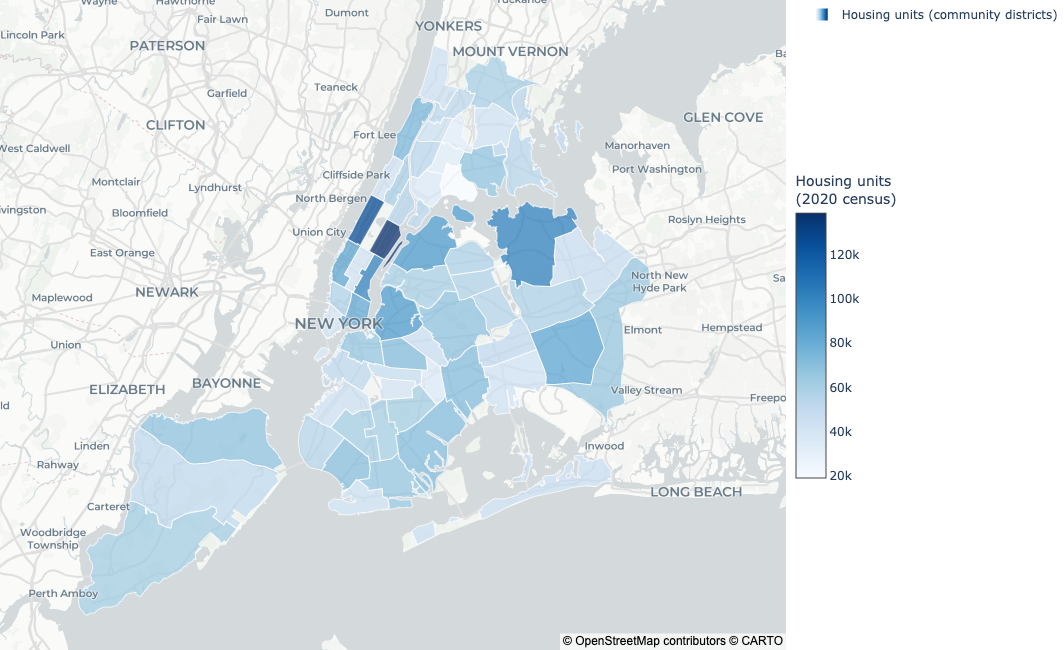

In [37]:
fig = go.Figure(housing_layer)

fig.update_layout(
    map_style="carto-positron",
    map_center={"lat": 40.71, "lon": -73.95},     # the middle of New York City
    map_zoom=9.5,
    height=650,
    margin={"l": 0, "r": 0, "t": 0, "b": 0},
)

fig.show()

## 3. Layer 2: ZIP area edges

Next, the outlines of the ZIP areas, so that we can see where the population bubbles come from. We use another `Choroplethmap`, but this time we make the **fill invisible**, with a color scale whose colors are fully transparent (`rgba(0,0,0,0)`: an alpha of 0 means see-through), and only keep the **lines**: thin and gray, so they stay in the background.

Every shape gets the same `z` value, because we don't need to color them by a number.

In [38]:
zip_edges = go.Choroplethmap(
    geojson=zip_shapes,
    locations=zips["zip"],
    featureidkey="properties.zip",
    z=[0] * len(zips),                        # the same value everywhere: we aren't coloring by a number
    colorscale=[[0, "rgba(0,0,0,0)"], [1, "rgba(0,0,0,0)"]],     # a fully transparent fill...
    showscale=False,                          # no color legend for this layer
    marker_line_color="#555555",              # ...with thin dark gray lines
    marker_line_width=0.6,
    hoverinfo="skip",
    showlegend=True,
    name="ZIP area edges",
)

## 4. Layer 3: population, as bubbles

A bubble is a *point*, not a shape, so we use `go.Scattermap()`, which draws a marker at a longitude and latitude. We use the center point that comes with each ZIP area.

**Sizing the bubbles.** The marker `size` is the bubble's *width* in pixels, but people read the *area* of a circle. If we made the width proportional to the population, an area with twice the people would look four times as big. Area is the width squared, so we make the width proportional to the **square root** of the population.

In [39]:
biggest_bubble = 26                           # the width, in pixels, of the bubble for the most populated area

# the square root of each population, divided by the largest square root, gives a number from 0 to 1.
# Multiply by biggest_bubble for the width in pixels
bubble_sizes = biggest_bubble * (zips["population"] / zips["population"].max()) ** 0.5

# the hover text for each bubble, built the same way, going through three columns at once
bubble_hover = []

for names, neighborhood, population in zip(zips["zip_codes"], zips["neighborhood"], zips["population"]):
    bubble_hover.append(f"<b>{names}</b><br>{neighborhood}<br>Population: {population}")

population_layer = go.Scattermap(
    lat=zips["lat"],
    lon=zips["lon"],
    mode="markers",
    marker={"size": bubble_sizes, "color": "#e6550d", "opacity": 0.55},      # a see-through orange
    text=bubble_hover,
    hoverinfo="text",
    showlegend=True,
    name="Population (ZIP areas)",
)

## 5. Put the layers together

`go.Figure()` takes a list of traces, and draws them in order, from the bottom to the top: first the filled districts, then the ZIP edges, then the bubbles on top (so that they can be hovered over).

In the legend, **clicking a layer's name turns it off and on**, so you can look at each one alone, or both together. (The "ZIP area edges" entry has no color swatch, because its fill is invisible.)

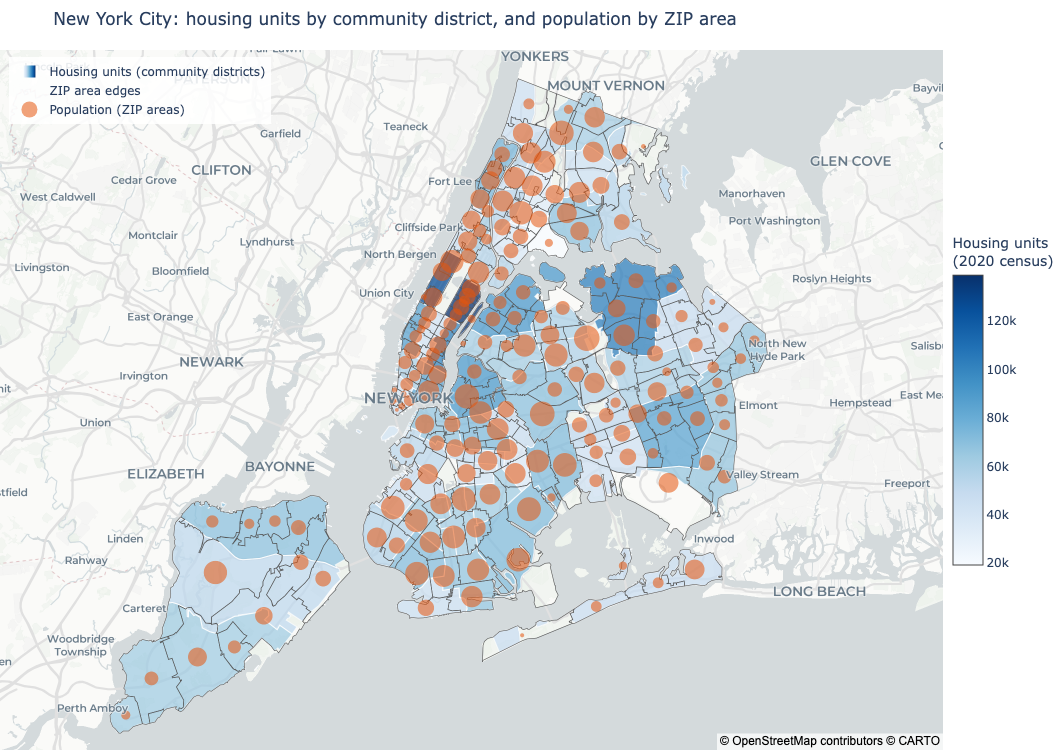

In [40]:
fig = go.Figure([housing_layer, zip_edges, population_layer])

fig.update_layout(
    title="New York City: housing units by community district, and population by ZIP area",
    map_style="carto-positron",
    map_center={"lat": 40.71, "lon": -73.95},
    map_zoom=9.7,
    height=750,
    margin={"l": 0, "r": 0, "t": 50, "b": 0},
    # put the legend in a corner of the map, on a white background
    legend={"x": 0.01, "y": 0.99, "bgcolor": "rgba(255,255,255,0.85)"},
)

fig.show()

Hover over a district, and then over a bubble. Click the legend to turn layers off and on.

## 6. An alternate rendering: two translucent fills

What if we used the "obvious" approach, and drew **both layers as filled maps**, each one see-through? Here, the community districts are filled in **red** (housing units), and the ZIP areas in **yellow** (population), each at 50% opacity.

Everything is the same as before, except that the ZIP layer is now a filled `Choroplethmap`, colored by population, instead of bubbles. The ZIP layer is drawn on top, so it's the one that responds to hovering.

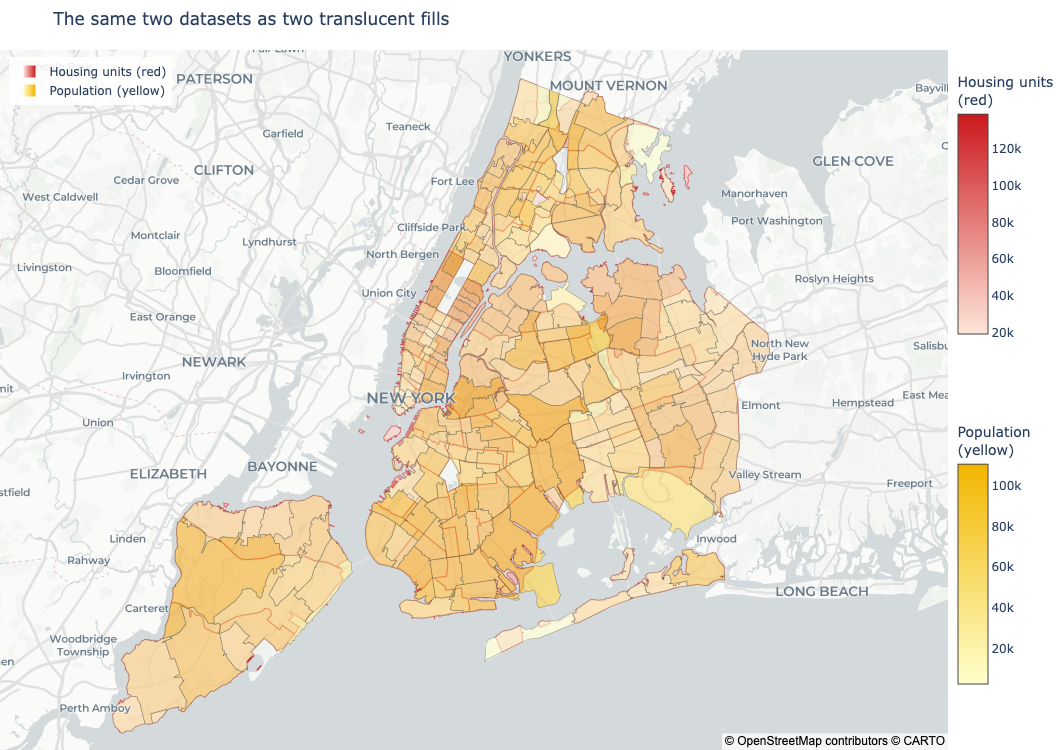

In [41]:
# housing units: community districts in shades of red, 50% see-through
housing_red = go.Choroplethmap(
    geojson=district_shapes,
    locations=districts["commntydst"],
    featureidkey="properties.commntydst",
    z=districts["housing_units"],
    colorscale=[[0, "#fee5d9"], [1, "#cb181d"]],         # from pale red to strong red
    marker_opacity=0.5,
    marker_line_color="#cb181d",
    marker_line_width=1,
    colorbar={"title": "Housing units<br>(red)", "x": 1.0, "y": 0.78, "len": 0.4},
    text=district_hover,
    hoverinfo="text",
    name="Housing units (red)",
    showlegend=True,
)

# population: ZIP areas in shades of yellow, also 50% see-through
population_yellow = go.Choroplethmap(
    geojson=zip_shapes,
    locations=zips["zip"],
    featureidkey="properties.zip",
    z=zips["population"],
    colorscale=[[0, "#ffffcc"], [1, "#f2b600"]],         # from pale yellow to strong yellow
    marker_opacity=0.5,
    marker_line_color="#555555",
    marker_line_width=0.6,
    colorbar={"title": "Population<br>(yellow)", "x": 1.0, "y": 0.28, "len": 0.4},
    text=bubble_hover,                                   # the hover text we made for the bubbles
    hoverinfo="text",
    name="Population (yellow)",
    showlegend=True,
)

fig = go.Figure([housing_red, population_yellow])

fig.update_layout(
    title="The same two datasets as two translucent fills",
    map_style="carto-positron",
    map_center={"lat": 40.71, "lon": -73.95},
    map_zoom=9.7,
    height=750,
    margin={"l": 0, "r": 0, "t": 50, "b": 0},
    legend={"x": 0.01, "y": 0.99, "bgcolor": "rgba(255,255,255,0.85)"},
)

fig.show()

## 7. The same idea in pydeck

pydeck can layer two datasets too. The idea is the same: one layer for the community districts in translucent **red**, and one for the ZIP areas in translucent **yellow**. The difference is **how the colors are set**. Plotly turned numbers into colors for us, with a color scale. In pydeck, we work out each shape's color ourselves, and store it in the shape's `properties`, as we did in Week 10.

(If you get a `No module named 'pydeck'` error, run `conda install -c conda-forge pydeck` in a terminal, and restart Jupyter.)

In [42]:
import pydeck as pdk
from IPython.display import HTML, IFrame

### Colors from numbers

We need a function that turns a number into a color. It blends between a pale color and a strong one: a `share` of 0 gives the pale color, and a share of 1 gives the strong one. A color in pydeck is a list of `[red, green, blue, alpha]`, with each number from 0 to 255. The alpha is the opacity, so 130 is about half see-through.

In [43]:
def blend(pale, strong, share):
    """A color a share (0 to 1) of the way from the pale color to the strong one, as [red, green, blue, alpha]."""
    color = []

    # a color has three channels: 0 is red, 1 is green, and 2 is blue. Blend each one in turn
    for channel in range(3):
        low = pale[channel]
        high = strong[channel]

        # share 0 gives the low number, and share 1 gives the high one. int() makes it a whole number
        color.append(int(low + (high - low) * share))

    color.append(130)          # the alpha: how opaque the color is, from 0 to 255

    return color


pale_red, strong_red = [254, 229, 217], [203, 24, 29]
pale_yellow, strong_yellow = [255, 255, 204], [242, 182, 0]

# the smallest and largest value of each dataset, to work out each share
least_units, most_units = districts["housing_units"].min(), districts["housing_units"].max()
least_people, most_people = zips["population"].min(), zips["population"].max()

# a dictionary for each table, to look up a row by its code: {101: {...}, 102: {...}, ...}
district_rows = districts.set_index("commntydst").to_dict("index")
zip_rows = zips.set_index("zip").to_dict("index")

print(blend(pale_red, strong_red, 0), blend(pale_red, strong_red, 1))

[254, 229, 217, 130] [203, 24, 29, 130]


Now we loop over the shapes and give each one a `color`, plus the text for its hover box. We do this for the districts (red) and for the ZIP areas (yellow).

(The loops below add to the shapes in place. That's fine, because the Plotly maps above only use the `commntydst` and `zip` properties.)

In [44]:
# the parks and airports have no row in our table of districts, so we leave their shapes out:
# build a new list with only the shapes whose code is in the table
real_districts = []

for feature in district_shapes["features"]:
    if feature["properties"]["commntydst"] in district_rows:
        real_districts.append(feature)

district_shapes["features"] = real_districts

# the community districts: a red that depends on the number of housing units
for feature in district_shapes["features"]:
    row = district_rows[feature["properties"]["commntydst"]]

    share = (row["housing_units"] - least_units) / (most_units - least_units)

    feature["properties"]["color"] = blend(pale_red, strong_red, share)
    feature["properties"]["label"] = row["label"]
    feature["properties"]["details"] = f"Housing units: {row['housing_units']}"
    feature["properties"]["units"] = row["housing_units"]

# the ZIP areas: a yellow that depends on the population
for feature in zip_shapes["features"]:
    row = zip_rows[feature["properties"]["zip"]]

    share = (row["population"] - least_people) / (most_people - least_people)

    feature["properties"]["color"] = blend(pale_yellow, strong_yellow, share)
    feature["properties"]["label"] = f"{row['zip_codes']}: {row['neighborhood']}"
    feature["properties"]["details"] = f"Population: {row['population']}"

district_shapes["features"][0]["properties"]

{'commntydst': 101,
 'color': [244, 190, 181, 130],
 'label': 'Manhattan CD 1',
 'details': 'Housing units: 41977',
 'units': 41977}

### The map

Each layer is a `GeoJsonLayer`, like in Week 10. We read each shape's color from its `color` property. Layers are drawn in order, so the second one is on top, and it's the one that responds to hovering. The hover box is the same for both layers, because we gave each shape a `label` and `details`.

We use `pitch=0`, a view straight down, so the map looks flat like the Plotly one.

In [45]:
red_layer = pdk.Layer(
    "GeoJsonLayer",
    data=district_shapes,
    get_fill_color="properties.color",
    get_line_color=[203, 24, 29],             # red outlines
    line_width_min_pixels=1,
    pickable=True,
)

yellow_layer = pdk.Layer(
    "GeoJsonLayer",
    data=zip_shapes,
    get_fill_color="properties.color",
    get_line_color=[85, 85, 85],              # dark gray outlines
    line_width_min_pixels=1,
    pickable=True,
)

deck = pdk.Deck(
    layers=[red_layer, yellow_layer],
    initial_view_state=pdk.ViewState(latitude=40.71, longitude=-73.95, zoom=9.5, pitch=0),
    map_style="light",
    tooltip={"html": "<b>{label}</b><br/>{details}"},
)

deck.to_html("nyc_layers_flat.html", open_browser=False)
IFrame("nyc_layers_flat.html", width="100%", height=650)

In [46]:
# pydeck doesn't make a legend, so we write one in HTML: a bar that fades from the pale color to the strong one
HTML(
    "<div style='font-family: sans-serif; font-size: 13px'>"
    "<b>Housing units</b> (red) &nbsp; "
    f"{least_units} <span style='display:inline-block; width:120px; height:12px; "
    "background:linear-gradient(to right, rgb(254,229,217), rgb(203,24,29))'></span>"
    f" {most_units}"
    "<br><b>Population</b> (yellow) &nbsp; "
    f"{least_people} <span style='display:inline-block; width:120px; height:12px; "
    "background:linear-gradient(to right, rgb(255,255,204), rgb(242,182,0))'></span>"
    f" {most_people}"
    "</div>"
)